<a href="https://colab.research.google.com/github/DaianaSep/Entrega-final/blob/main/Sepulveda_Daiana_Entrega_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Entrega Final: Notebook Integral de Ciencia de Datos
## Detección de burnout alto en desarrolladores
**Estudiante:** Daiana Sepúlveda  
**Proyecto:** Análisis de desgaste profesional y estrés en desarrolladores

## 1. Definición del problema y variables del dataset

Para esta entrega decidí continuar con el dataset sobre burnout en desarrolladores que venía trabajando en las entregas anteriores. Me interesa analizar cómo se relacionan los hábitos laborales y personales con el desgaste profesional, y evaluar si puedo identificar los casos de burnout alto.

Es un problema de **clasificación binaria**: agrupé los niveles bajo y medio en una categoría (0), y mantuve el nivel alto como la categoría que quiero detectar (1).

**Pregunta principal:** ¿qué tan bien puedo identificar los casos de burnout alto a partir de la jornada laboral, el descanso y la actividad diaria, sin utilizar directamente el puntaje de estrés?

La idea es que este análisis pueda servir como punto de partida para revisar la carga de trabajo y pensar acciones de bienestar dentro de un equipo. Para aplicarlo en una situación real, primero sería necesario validar los datos y comprobar cómo funciona el modelo en ese contexto.

| Variable | Tipo y significado | Uso y aporte esperado |
|---|---|---|
| `age` | Numérica; edad en años | Solo filtro de coherencia edad-experiencia; excluida del modelo. |
| `experience_years` | Numérica; años de experiencia | Solo filtro de coherencia con edad; excluida del modelo. |
| `daily_work_hours` | Numérica; horas de trabajo diario | Indicador de duración de jornada y posible sobrecarga. |
| `sleep_hours` | Numérica; horas de sueño | Información de descanso, diferente de la jornada. |
| `caffeine_intake` | Numérica; consumo registrado, unidad no documentada | Indicador exploratorio de hábitos; no se interpreta como dosis. |
| `bugs_per_day` | Numérica; errores por día | Describe incidencias laborales; puede ser antecedente, consecuencia o correlato del desgaste. |
| `commits_per_day` | Numérica; commits por día | Describe actividad de desarrollo; no equivale automáticamente a productividad. |
| `meetings_per_day` | Numérica; reuniones por día | Aproxima carga de coordinación y posibles interrupciones. |
| `screen_time` | Numérica; horas de pantalla registradas | Complementa la jornada, aunque ambas están muy correlacionadas. |
| `exercise_hours` | Numérica; horas de ejercicio registradas | Aporta actividad personal; la periodicidad debe verificarse en la fuente. |
| `stress_level` | Numérica; puntaje de estrés | Solo limpieza y EDA; excluida por posible cercanía con la construcción de la etiqueta. |
| `burnout_level` | Categórica; Low, Medium o High | Objetivo transformado a binario; nunca predictor. |
| `categoria_jornada` | Categórica derivada de horas de trabajo | Tres tramos fijos, codificados con One-Hot dentro del pipeline. |


In [34]:
from pathlib import Path
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

SEMILLA = 42
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
AZUL, NARANJA = '#246B83', '#D56746'
archivo = Path('developer_burnout_dataset_7000.csv')
url = 'https://raw.githubusercontent.com/DaianaSep/pre-entrega-4/refs/heads/main/developer_burnout_dataset_7000.csv'

df = pd.read_csv(url)
print('Dimensiones originales:', df.shape)
display(df.head())
df.info()
display(df.describe().round(2))

Dimensiones originales: (7000, 12)


,age,experience_years,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,stress_level,burnout_level
0,26.0,12.0,10.33,4.45,2.0,11.0,4.0,1.0,15.07,0.14,55.96,Medium
1,39.0,10.0,8.62,5.77,5.0,15.0,11.0,5.0,13.25,0.54,82.22,High
2,34.0,13.0,NaN,4.03,5.0,2.0,18.0,9.0,11.18,1.54,61.77,Medium
3,30.0,1.0,6.85,6.47,2.0,15.0,26.0,1.0,11.14,0.96,54.98,Medium
4,27.0,7.0,4.24,5.80,NaN,9.0,17.0,7.0,8.05,0.36,27.90,Low


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               6860 non-null   float64
 1   experience_years  6860 non-null   float64
 2   daily_work_hours  6860 non-null   float64
 3   sleep_hours       6860 non-null   float64
 4   caffeine_intake   6860 non-null   float64
 5   bugs_per_day      6860 non-null   float64
 6   commits_per_day   6860 non-null   float64
 7   meetings_per_day  6860 non-null   float64
 8   screen_time       6860 non-null   float64
 9   exercise_hours    6860 non-null   float64
 10  stress_level      6860 non-null   float64
 11  burnout_level     6860 non-null   object 
dtypes: float64(11), object(1)
memory usage: 656.4+ KB


,age,experience_years,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,stress_level
count,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00,6860.00
mean,32.13,9.58,9.00,6.49,3.54,9.48,14.46,4.55,11.97,1.01,53.65
std,7.23,5.76,2.86,1.45,2.28,5.75,8.67,2.86,3.09,0.58,23.45
min,20.00,0.00,4.00,4.00,0.00,0.00,0.00,0.00,5.21,0.00,0.00
25%,26.00,5.00,6.56,5.22,2.00,5.00,7.00,2.00,9.46,0.51,36.59
50%,32.00,10.00,8.99,6.46,4.00,9.00,14.00,5.00,12.02,1.02,53.80
75%,38.00,15.00,11.42,7.74,6.00,14.00,22.00,7.00,14.42,1.51,70.80
max,44.00,19.00,14.00,9.00,7.00,19.00,29.00,9.00,18.93,2.00,100.00


### 2.1. Saneamiento

Primero normalicé los nombres de los niveles de burnout, convertí las columnas numéricas y eliminé los duplicados. Mantuve los filtros de las entregas anteriores: horas de trabajo mayores que cero, estrés no negativo y una diferencia de al menos 18 años entre edad y experiencia. Este último filtro es un criterio del proyecto y puede dejar afuera algunos casos válidos.

También eliminé los registros sin un nivel de burnout válido o sin datos para aplicar los filtros. Los demás faltantes se completan con la mediana en variables numéricas y la moda en categóricas, calculadas solo con los datos de entrenamiento de cada partición de validación.

La tabla siguiente muestra cuántos registros se excluyeron en cada paso. Estas decisiones pueden afectar qué casos quedan representados en el análisis.

In [23]:
datos = df.copy()
objetivo = 'burnout_level'
numericas_originales = [x for x in df.columns if x != objetivo]
conversiones = {}
for col in numericas_originales:
    nueva = pd.to_numeric(datos[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    conversiones[col] = int((datos[col].notna() & nueva.isna()).sum())
    datos[col] = nueva
datos[objetivo] = datos[objetivo].astype('string').str.strip().str.title()
display(pd.DataFrame({'Nulos originales': df.isna().sum(),
                      'Nulos (%)': df.isna().mean().mul(100)})
        .sort_values('Nulos (%)', ascending=False).round(2))
print('Valores convertidos a nulos:', conversiones)
auditoria = []
def registrar_paso(nombre, mascara):
    global datos
    antes = len(datos)
    datos = datos.loc[mascara].copy()
    auditoria.append({'Paso': nombre, 'Excluidos': antes-len(datos), 'Restantes': len(datos)})
registrar_paso('Duplicados exactos', ~datos.duplicated())
registrar_paso('Etiqueta válida', datos[objetivo].isin(['Low', 'Medium', 'High']))
registrar_paso('Jornada mayor que cero', datos.daily_work_hours > 0)
registrar_paso('Estrés no negativo', datos.stress_level >= 0)
registrar_paso('Edad menos experiencia >= 18', datos.age-datos.experience_years >= 18)
display(pd.DataFrame(auditoria))
datos = datos.reset_index(drop=True)
y = datos[objetivo].eq('High').astype(int)
# Se reserva la prueba ANTES de explorar y tomar decisiones sobre patrones.
idx_train, idx_test = train_test_split(datos.index, test_size=.20, stratify=y, random_state=SEMILLA)
eda = datos.loc[idx_train].copy()
print(f'Entrenamiento: {len(idx_train)} | Prueba reservada: {len(idx_test)}')

,Nulos originales,Nulos (%)
age,140,2.0
experience_years,140,2.0
daily_work_hours,140,2.0
sleep_hours,140,2.0
caffeine_intake,140,2.0
bugs_per_day,140,2.0
commits_per_day,140,2.0
meetings_per_day,140,2.0
screen_time,140,2.0
exercise_hours,140,2.0


Valores convertidos a nulos: {'age': 0, 'experience_years': 0, 'daily_work_hours': 0, 'sleep_hours': 0, 'caffeine_intake': 0, 'bugs_per_day': 0, 'commits_per_day': 0, 'meetings_per_day': 0, 'screen_time': 0, 'exercise_hours': 0, 'stress_level': 0}


,Paso,Excluidos,Restantes
0,Duplicados exactos,0,7000
1,Etiqueta válida,140,6860
2,Jornada mayor que cero,140,6720
3,Estrés no negativo,137,6583
4,Edad menos experiencia >= 18,2139,4444


Entrenamiento: 3555 | Prueba reservada: 889


### 2.2. Exploración del entrenamiento
Para los gráficos y la revisión de valores atípicos usé solo los datos de entrenamiento. Dejé los de prueba para la evaluación final. Conservé los valores atípicos detectados con el método IQR, porque un dato poco común no significa que esté mal.

In [24]:
q1 = eda[numericas_originales].quantile(.25)
q3 = eda[numericas_originales].quantile(.75)
iqr = q3-q1
atipicos = ((eda[numericas_originales] < q1-1.5*iqr) | (eda[numericas_originales] > q3+1.5*iqr)).sum()
display(pd.DataFrame({'Mínimo': eda[numericas_originales].min(),
    'Mediana': eda[numericas_originales].median(), 'Máximo': eda[numericas_originales].max(),
    'Atípicos (IQR)': atipicos}).round(2))

,Mínimo,Mediana,Máximo,Atípicos (IQR)
age,20.00,36.00,44.00,0
experience_years,0.00,7.00,19.00,0
daily_work_hours,4.00,8.96,14.00,0
sleep_hours,4.00,6.46,9.00,0
caffeine_intake,0.00,4.00,7.00,0
bugs_per_day,0.00,9.00,19.00,0
commits_per_day,0.00,14.00,29.00,0
meetings_per_day,0.00,5.00,9.00,0
screen_time,5.24,11.95,18.93,0
exercise_hours,0.00,1.01,2.00,0


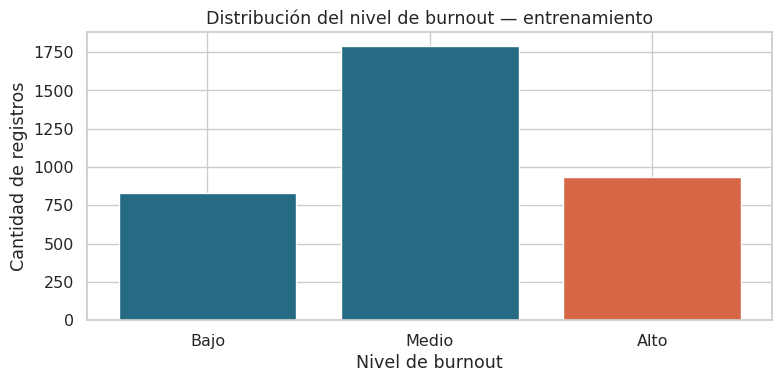

**Interpretación:** 937 de 3555 registros (26.4%) tienen burnout alto. La frecuencia de la clase positiva permite contextualizar recall, precisión y average precision; accuracy por sí sola resulta insuficiente.

In [25]:
conteos = eda.burnout_level.value_counts().reindex(['Low','Medium','High'], fill_value=0)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(['Bajo','Medio','Alto'], conteos, color=[AZUL,AZUL,NARANJA])
ax.set(title='Distribución del nivel de burnout — entrenamiento', xlabel='Nivel de burnout', ylabel='Cantidad de registros')
plt.tight_layout(); plt.show()
display(Markdown(f'**Interpretación:** {conteos["High"]} de {len(eda)} registros ({conteos["High"]/len(eda):.1%}) tienen burnout alto. La frecuencia de la clase positiva permite contextualizar recall, precisión y average precision; accuracy por sí sola resulta insuficiente.'))

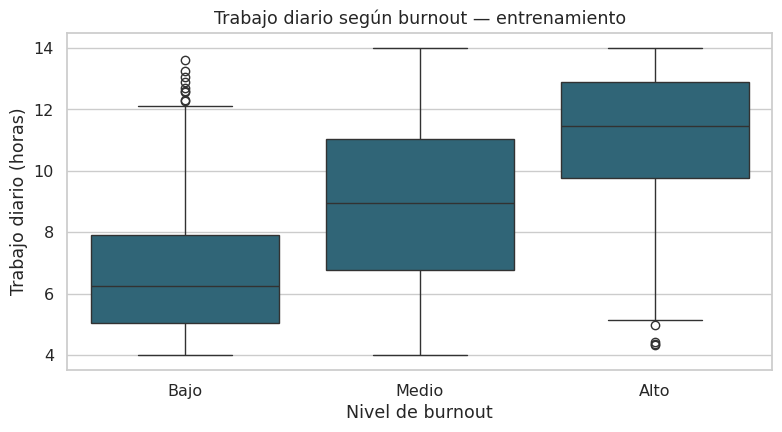

**Interpretación:** las medianas de jornada son Low: 6.25 h, Medium: 8.95 h, High: 11.47 h. La comparación muestra asociación entre jornada y etiqueta; no demuestra que reducir horas cause un cambio equivalente en burnout.

In [26]:
fig, ax = plt.subplots(figsize=(8,4.5))
sns.boxplot(data=eda, x='burnout_level', y='daily_work_hours', order=['Low','Medium','High'], color=AZUL, ax=ax)
ax.set(title='Trabajo diario según burnout — entrenamiento', xlabel='Nivel de burnout', ylabel='Trabajo diario (horas)')
ax.set_xticks(range(3), ['Bajo','Medio','Alto'])
plt.tight_layout(); plt.show()
medianas = eda.groupby('burnout_level').daily_work_hours.median()
display(Markdown('**Interpretación:** las medianas de jornada son '+', '.join(f'{k}: {medianas[k]:.2f} h' for k in ['Low','Medium','High'])+'. La comparación muestra asociación entre jornada y etiqueta; no demuestra que reducir horas cause un cambio equivalente en burnout.'))

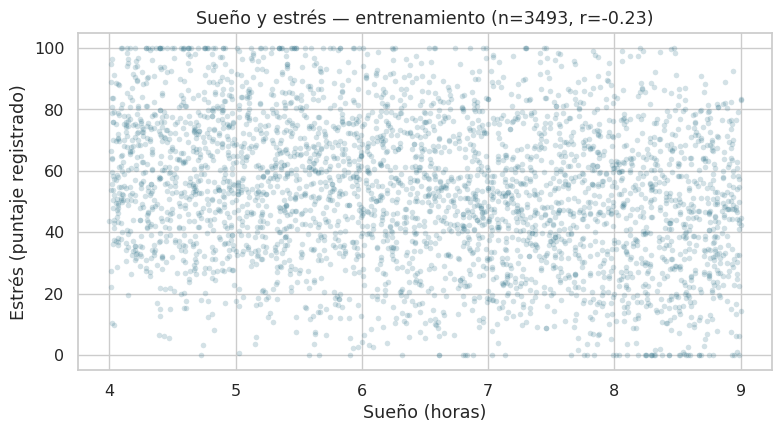

**Interpretación:** la correlación lineal entre sueño y estrés es -0.23. La dispersión permite evaluar cuánto se solapan los registros; esta relación no basta para explicar cada caso individual.

In [27]:
d = eda.dropna(subset=['sleep_hours','stress_level'])
r = d.sleep_hours.corr(d.stress_level)
fig, ax = plt.subplots(figsize=(8,4.5))
sns.scatterplot(data=d, x='sleep_hours', y='stress_level', color=AZUL, alpha=.2, s=16, linewidth=0, ax=ax)
ax.set(title=f'Sueño y estrés — entrenamiento (n={len(d)}, r={r:.2f})', xlabel='Sueño (horas)', ylabel='Estrés (puntaje registrado)')
plt.tight_layout(); plt.show()
display(Markdown(f'**Interpretación:** la correlación lineal entre sueño y estrés es {r:.2f}. La dispersión permite evaluar cuánto se solapan los registros; esta relación no basta para explicar cada caso individual.'))

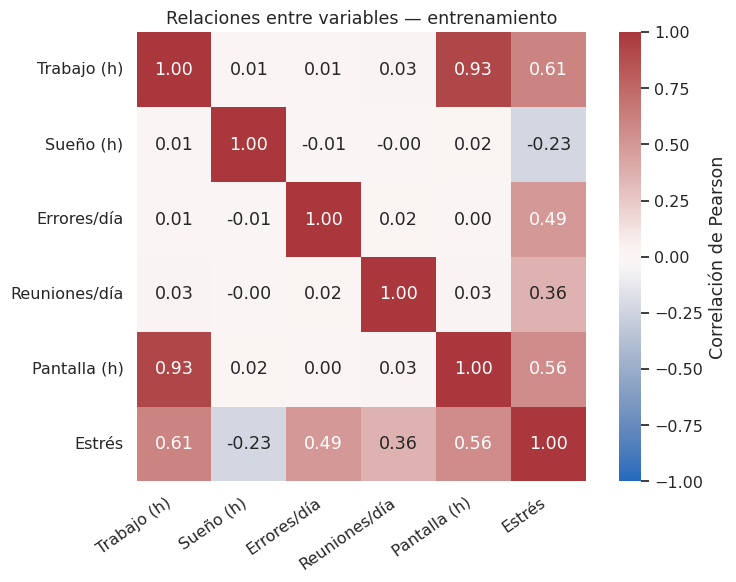

**Interpretación:** trabajo y pantalla tienen una correlación de 0.93; trabajo y estrés, de 0.61. Las correlaciones usan pares disponibles, por lo que el número de observaciones puede variar. Una asociación alta entre predictores puede aportar información redundante.

In [28]:
variables = ['daily_work_hours','sleep_hours','bugs_per_day','meetings_per_day','screen_time','stress_level']
etiquetas = ['Trabajo (h)','Sueño (h)','Errores/día','Reuniones/día','Pantalla (h)','Estrés']
corr = eda[variables].corr()
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
    xticklabels=etiquetas, yticklabels=etiquetas, square=True, cbar_kws={'label':'Correlación de Pearson'}, ax=ax)
ax.set_title('Relaciones entre variables — entrenamiento')
plt.xticks(rotation=35, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()
display(Markdown(f'**Interpretación:** trabajo y pantalla tienen una correlación de {corr.loc["daily_work_hours","screen_time"]:.2f}; trabajo y estrés, de {corr.loc["daily_work_hours","stress_level"]:.2f}. Las correlaciones usan pares disponibles, por lo que el número de observaciones puede variar. Una asociación alta entre predictores puede aportar información redundante.'))

## 3. Preprocesamiento y feature engineering

Para el modelo usé las variables de jornada, sueño, cafeína, errores, commits, reuniones, tiempo de pantalla y ejercicio.

Dejé afuera `burnout_level` porque es lo que quiero predecir, y edad y experiencia para no usar esos datos personales como criterio. También excluí `stress_level`, porque no sé cómo se definieron los niveles de burnout y podría estar directamente relacionado con esa clasificación.

Retomé mi función para clasificar la jornada en reducida (menos de 8 horas), completa (entre 8 y 10 horas) y excesiva (más de 10 horas). Esta categoría se obtiene de las horas de trabajo, así que en el futuro podría comparar si agregarla mejora el modelo.

Completé los faltantes numéricos con la mediana y apliqué escalado estándar para la regresión logística. Para la categoría de jornada usé la moda y codificación One-Hot. Estos pasos se ajustan dentro del pipeline usando solo los datos de entrenamiento de cada partición de validación, para evitar incorporar información de prueba.

In [29]:
def categorizar_jornada(horas):
    if pd.isna(horas):
        return np.nan
    elif horas > 10:
        return 'Jornada Excesiva'
    elif horas >= 8:
        return 'Jornada Completa'
    return 'Jornada Reducida'

numericas = ['daily_work_hours','sleep_hours','caffeine_intake','bugs_per_day',
             'commits_per_day','meetings_per_day','screen_time','exercise_hours']
X = datos[numericas].copy()
X['categoria_jornada'] = X.daily_work_hours.apply(categorizar_jornada)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

def preprocesador(escalar=True):
    pasos = [('imputacion', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('escalado', StandardScaler()))
    return ColumnTransformer([
        ('numericas', Pipeline(pasos), numericas),
        ('categoricas', Pipeline([
            ('imputacion', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['categoria_jornada'])])
print('Predictores finales:', X_train.columns.tolist())
print('Objetivo:', objetivo, '| Positivo: High (1)')
print('Excluidas del modelo: age, experience_years, stress_level, burnout_level')
display(X_train.head())

Predictores finales: ['daily_work_hours', 'sleep_hours', 'caffeine_intake', 'bugs_per_day', 'commits_per_day', 'meetings_per_day', 'screen_time', 'exercise_hours', 'categoria_jornada']
Objetivo: burnout_level | Positivo: High (1)
Excluidas del modelo: age, experience_years, stress_level, burnout_level


,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,categoria_jornada
1782,8.52,4.91,3.0,9.0,18.0,7.0,10.67,1.32,Jornada Completa
2792,11.59,8.73,1.0,19.0,19.0,8.0,15.36,0.63,Jornada Excesiva
1506,6.25,6.36,4.0,0.0,5.0,0.0,9.88,1.69,Jornada Reducida
2198,13.90,5.61,1.0,14.0,11.0,1.0,16.54,0.17,Jornada Excesiva
637,8.23,8.57,2.0,19.0,4.0,2.0,11.88,1.53,Jornada Completa


## 4. Modelado y evaluación
### 4.1. Comparación dentro del entrenamiento
Dividí los datos en 80 % para entrenamiento y 20 % para prueba, manteniendo la proporción de casos de burnout alto en ambos grupos. Usé la semilla 42 para poder repetir la misma división.

Comparé regresión logística y Random Forest, dando más peso a la clase menos frecuente. También agregué como referencia un modelo que siempre predice la categoría más común.

Elegí el modelo con mayor F1 promedio en una validación cruzada de cinco particiones del entrenamiento. Esta métrica combina precisión y recall, considerando tanto las alertas falsas como los casos altos que no se detectan.

Mantuve el umbral de clasificación en 0,5 y reservé los datos de prueba para la evaluación final.

In [30]:
modelos = {
    'Referencia mayoritaria': Pipeline([('preparacion', preprocesador(False)), ('modelo', DummyClassifier(strategy='most_frequent'))]),
    'Regresión Logística': Pipeline([('preparacion', preprocesador()), ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA))]),
    'Random Forest': Pipeline([('preparacion', preprocesador(False)), ('modelo', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEMILLA, n_jobs=1))])}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv,
        scoring={'f1':'f1','recall':'recall','ap':'average_precision'}, n_jobs=1)
    filas.append({'Modelo': nombre, 'F1 medio': scores['test_f1'].mean(),
        'F1 desvío': scores['test_f1'].std(), 'Recall medio': scores['test_recall'].mean(),
        'AP media': scores['test_ap'].mean()})
validacion = pd.DataFrame(filas).set_index('Modelo').sort_values('F1 medio', ascending=False)
display(validacion.round(4))
nombre_elegido = validacion.index[0]
print('Modelo elegido sin consultar prueba:', nombre_elegido)

,F1 medio,F1 desvío,Recall medio,AP media
Modelo,,,,
Regresión Logística,0.7725,0.0113,0.8805,0.8793
Random Forest,0.7246,0.0253,0.6511,0.8308
Referencia mayoritaria,0.0000,0.0000,0.0000,0.2636


Modelo elegido sin consultar prueba: Regresión Logística


### 4.2. Evaluación final en prueba
Después de elegir el modelo mediante validación cruzada, entrené ambos modelos con todos los datos de entrenamiento y los evalué con los mismos datos de prueba. Esta comparación final no cambia la elección anterior.

La precisión indica qué proporción de las alertas es correcta; el recall, qué proporción de los casos altos detecta; y F1 combina ambas métricas. AUC-ROC y AP evalúan qué tan bien el modelo distingue los casos altos usando sus probabilidades.

Para las curvas ROC utilicé las probabilidades de burnout alto obtenidas con `predict_proba`. Las matrices de confusión y las métricas de clasificación usan un umbral de 0,5: desde ese valor, el modelo clasifica el caso como alto. Estas probabilidades todavía no se comprobaron como medidas de riesgo real.


,Accuracy,Precisión,Recall,F1,AUC-ROC,AP
Modelo,,,,,,
Referencia mayoritaria,0.7368,0.0000,0.0000,0.0000,0.5000,0.2632
Regresión Logística,0.8729,0.7065,0.8846,0.7856,0.9528,0.8793
Random Forest,0.8864,0.8376,0.7051,0.7657,0.9458,0.8477


Proporción de burnout alto en prueba: 0.2632


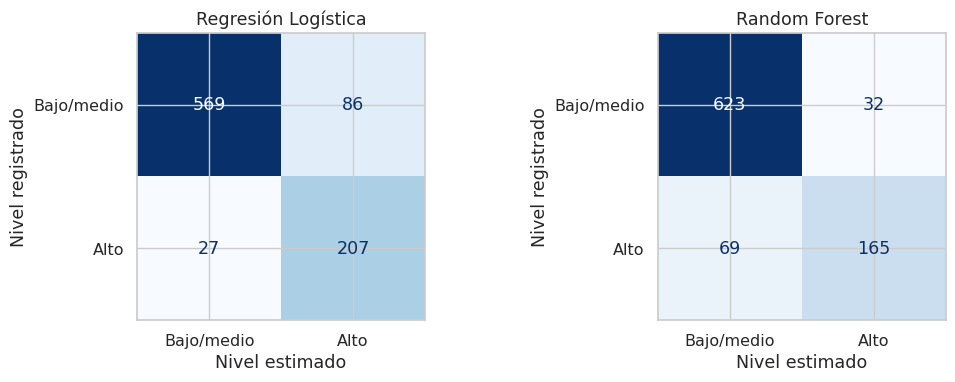

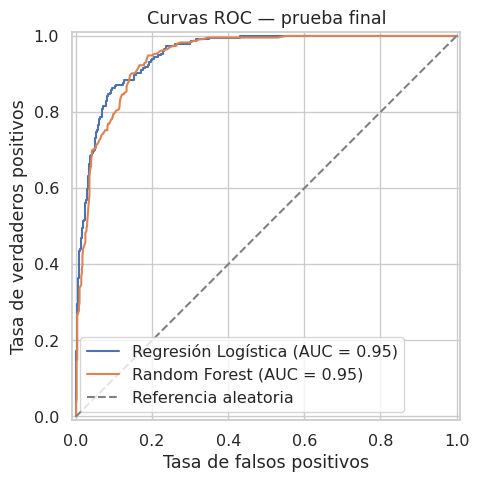

**Interpretación:** el modelo elegido (Regresión Logística) omite 27 casos altos y genera 86 alertas falsas en esta prueba. Estos errores muestran por qué una alerta necesita revisión y por qué no debe interpretarse una ausencia de alerta como garantía de bienestar.

In [31]:
filas, predicciones, probabilidades = [], {}, {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:,1]
    predicciones[nombre], probabilidades[nombre] = pred, prob
    filas.append({'Modelo':nombre, 'Accuracy':accuracy_score(y_test,pred),
        'Precisión':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0), 'F1':f1_score(y_test,pred,zero_division=0),
        'AUC-ROC':roc_auc_score(y_test,prob), 'AP':average_precision_score(y_test,prob)})
resultados = pd.DataFrame(filas).set_index('Modelo')
display(resultados.round(4))
print(f'Proporción de burnout alto en prueba: {y_test.mean():.4f}')
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, nombre in zip(axes, ['Regresión Logística','Random Forest']):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], labels=[0,1],
        display_labels=['Bajo/medio','Alto'], cmap='Blues', colorbar=False, ax=ax)
    ax.set(title=nombre, xlabel='Nivel estimado', ylabel='Nivel registrado')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,5))
for nombre in ['Regresión Logística','Random Forest']:
    RocCurveDisplay.from_predictions(y_test, probabilidades[nombre], name=nombre, ax=ax)
ax.plot([0,1],[0,1],'--',color='gray',label='Referencia aleatoria')
ax.set(title='Curvas ROC — prueba final', xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
ax.legend(); plt.tight_layout(); plt.show()
pred = predicciones[nombre_elegido]
fn = int(((y_test==1)&(pred==0)).sum())
fp = int(((y_test==0)&(pred==1)).sum())
display(Markdown(f'**Interpretación:** el modelo elegido ({nombre_elegido}) omite {fn} casos altos y genera {fp} alertas falsas en esta prueba. Estos errores muestran por qué una alerta necesita revisión y por qué no debe interpretarse una ausencia de alerta como garantía de bienestar.'))

### 4.3. Variables que utiliza el modelo
Para ver qué variables utiliza más el modelo, cambié al azar los valores de una variable por vez en los datos de entrenamiento y observé cuánto bajaba el F1. Una caída mayor indica que el modelo depende más de esa variable. Como algunas variables están relacionadas, pueden compartir importancia. Este análisis ayuda a entender el modelo, pero no demuestra qué causa el burnout.

In [32]:
importancias = permutation_importance(modelos[nombre_elegido], X_train, y_train,
    scoring='f1', n_repeats=5, random_state=SEMILLA, n_jobs=1)
ranking = pd.DataFrame({'Variable':X.columns, 'Caída F1':importancias.importances_mean,
                        'Desvío':importancias.importances_std}).sort_values('Caída F1', ascending=False)
display(ranking.round(4))

,Variable,Caída F1,Desvío
0,daily_work_hours,0.2209,0.0096
3,bugs_per_day,0.1888,0.0069
5,meetings_per_day,0.0933,0.0043
1,sleep_hours,0.0410,0.0031
2,caffeine_intake,0.0393,0.0062
7,exercise_hours,0.0145,0.0028
6,screen_time,-0.0034,0.0024
8,categoria_jornada,-0.0038,0.0028
4,commits_per_day,-0.0046,0.0018


## 5. Conclusiones y recomendaciones
### Resultados del proyecto

In [33]:
fila = resultados.loc[nombre_elegido]

display(Markdown(
    f'Después de limpiar los datos, trabajé con **{len(datos):,} de los '
    f'{len(df):,} registros originales**. Las conclusiones se basan en '
    'los casos que cumplieron los criterios de limpieza.\n\n'
    f'El modelo elegido fue **{nombre_elegido}**, porque logró el mejor '
    'equilibrio entre detectar casos altos y generar alertas correctas '
    'durante la validación.\n\n'
    f'En la prueba final detectó aproximadamente el **{fila["Recall"]:.0%} '
    'de los casos de burnout alto**, y cerca del '
    f'**{fila["Precisión"]:.0%} de las alertas que generó fueron correctas**.\n\n'
    'Estos resultados corresponden a los datos analizados. Antes de usar '
    'el modelo en otros equipos, sería necesario comprobar cómo funciona '
    'con información nueva.'
))

Después de limpiar los datos, trabajé con **4,444 de los 7,000 registros originales**. Las conclusiones se basan en los casos que cumplieron los criterios de limpieza.

El modelo elegido fue **Regresión Logística**, porque logró el mejor equilibrio entre detectar casos altos y generar alertas correctas durante la validación.

En la prueba final detectó aproximadamente el **88% de los casos de burnout alto**, y cerca del **71% de las alertas que generó fueron correctas**.

Estos resultados corresponden a los datos analizados. Antes de usar el modelo en otros equipos, sería necesario comprobar cómo funciona con información nueva.

### Aprendizaje y próximos pasos

En los datos de entrenamiento observé que los registros con burnout alto tienen jornadas más largas: la mediana pasa de 6,25 horas en el nivel bajo a 11,47 horas en el alto. También encontré una relación negativa débil entre sueño y estrés (r = −0,23), y una relación fuerte entre horas de trabajo y tiempo de pantalla (r = 0,93). Estas relaciones no permiten afirmar que una variable cause burnout.

Elegí regresión logística porque obtuvo el mayor F1 promedio en validación cruzada: 0,773 frente a 0,722 de Random Forest. En la prueba final también tuvo un F1 mayor (0,786 frente a 0,759) y detectó más casos altos: dejó sin detectar 27, frente a 70 de Random Forest. A cambio, generó más alertas falsas: 86 frente a 34.

Para el objetivo preventivo del proyecto, considero más importante detectar la mayor cantidad posible de casos altos, aunque después haya que revisar más alertas. Por eso, el mayor recall de la regresión logística resulta útil. Antes de aplicarlo habría que evaluar si el equipo puede realizar ese seguimiento. Cualquier cambio en el umbral debería probarse con los datos de entrenamiento.

Propongo revisar las jornadas, las reuniones y las posibilidades de descanso de forma general y voluntaria. Si el modelo se valida con datos documentados, podría ayudar a orientar conversaciones de bienestar y revisar la distribución de tareas. No usaría sus resultados para sancionar ni evaluar el rendimiento individual.

### Plan de seguimiento

Propongo una prueba de ocho semanas: dos para registrar la situación inicial y seis para hacer el seguimiento. Antes habría que confirmar el origen de los datos, cómo se definió burnout y si las variables estarían disponibles al momento de usar el modelo.

El área de Bienestar acompañaría el seguimiento voluntario, la persona responsable del equipo revisaría las cargas y el equipo de Datos controlaría la calidad de la información y los resultados.

Las siguientes son metas iniciales para acordar antes de la prueba, no resultados obtenidos en este trabajo.

| Qué revisaría | Cómo lo mediría | Meta inicial propuesta |
|---|---|---|
| Calidad de los datos | Revisar semanalmente los faltantes y los registros excluidos. | Investigar aumentos de más de 5 puntos porcentuales respecto del inicio. |
| Seguimiento de alertas | Comparar las alertas generadas con las revisadas cada semana. | Revisar al menos el 90 % dentro de cinco días hábiles. |
| Resultados del modelo | Calcular precisión, recall y F1 al cierre, con etiquetas verificadas y suficientes casos. | Buscar un recall de al menos 0,85 y una precisión de 0,65. |
| Carga de trabajo | Medir por equipo la proporción de jornadas de más de 10 horas. | Buscar una reducción relativa del 10 % respecto del inicio. |
| Diferencias entre grupos | Comparar faltantes, exclusiones y errores cuando haya datos suficientes y autorización. | Investigar diferencias persistentes antes de ampliar el uso. |

Reducir las jornadas largas no significa necesariamente reducir el burnout. Para evaluar un cambio en el bienestar, también necesitaría mediciones voluntarias antes y después y una comparación adecuada. Con este dataset no puedo comprobar el efecto de una intervención.

### Limitaciones y próximos pasos

- **Origen de los datos:** no pude verificar cómo se recolectaron ni cómo se definieron los niveles de burnout. Esto limita la interpretación de las métricas.
- **Filtros aplicados:** algunas decisiones de limpieza pueden dejar afuera casos válidos. Revisaría especialmente el criterio de edad y experiencia.
- **Falta de fechas e identificadores:** no puedo comprobar si hay varias observaciones de una misma persona ni evaluar cambios a lo largo del tiempo.
- **Validación:** probaría el modelo con datos de otros equipos y revisaría si funciona de manera similar entre distintos grupos.
- **Uso del modelo:** antes de aplicarlo, evaluaría el costo de las alertas falsas, los casos no detectados y la capacidad de seguimiento. También comprobaría si sus probabilidades representan bien el riesgo observado.
- **Categoría de jornada:** compararía los resultados con y sin esta variable para ver si aporta algo además de las horas originales.